# Phase 12 — KUB Oracle ROI / Zoom Upper-Bound Study

**Oracle upper-bound; not deployable.** GT masks define component crop coordinates on KUB FULL_FIELD VAL only. GT pixels are never model input. The frozen UNet++ checkpoint and threshold 0.5 are unchanged. TEST and external data were not accessed.

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd().resolve(); ROOT=ROOT.parent if ROOT.name=='notebooks' else ROOT
T=ROOT/'reports/tables'; F=ROOT/'reports/figures/phase12_oracle_roi'; Q=ROOT/'reports/qualitative/phase12_oracle_roi'; C=ROOT/'data_cache/phase12_oracle_roi'
per_image=pd.read_csv(T/'phase12_oracle_roi_per_image.csv'); per_component=pd.read_csv(T/'phase12_oracle_roi_per_component.csv'); geometry=pd.read_csv(T/'phase12_oracle_crop_geometry.csv'); summary=pd.read_csv(T/'phase12_oracle_roi_summary.csv')
assert len(per_image)==106 and len(per_component)==156 and len(geometry)==156
print('Governance PASS: phase4_v2; FULL_FIELD VAL only; TEST NOT ACCESSED; cache-backed; no training')

Governance PASS: phase4_v2; FULL_FIELD VAL only; TEST NOT ACCESSED; cache-backed; no training


## Phase-11 motivation and Oracle definition

One GT-guided original-space square crop per component is resized to 512×512. Frozen UNet++ predicts from the **one-channel image crop only**. Restored component probabilities are fused by pixelwise MAX, followed by the fixed 0.5 threshold. Margins 10%, 25% (primary), and 50% were predeclared.

## Reproducible crop geometry and example

In [2]:
display(geometry.head())
print('Median primary-margin effective magnification:',geometry.mag_25.median())

,sample_id,patient_id,category,component_id,kub_size_v1_stratum,component_pixels,bbox_height,bbox_width,crop_side_10,mag_10,crop_side_25,mag_25,crop_side_50,mag_50
0,66b947d8ead11ae1260bc3142ca1707d,patient-00001,Bladder_Stone,1,TINY,522,31,24,37,13.837838,47,10.893617,63,8.126984
1,608acc38d4a151803e72f2f033ade67e,patient-00002,Bladder_Stone,1,MEDIUM,4955,84,97,117,4.376068,145,3.531034,193,2.652850
2,774123a57e11f802de7ed923c13b7120,patient-00007,Bladder_Stone,1,TINY,841,38,30,46,11.130435,58,8.827586,76,6.736842
3,68509b1fa766f0a9bb074a3640f5ea05,patient-00011,Bladder_Stone,1,TINY,848,29,41,49,10.448980,61,8.393443,81,6.320988
4,f5a92a209cd5010d230ecaab8556ef89,patient-00012,Bladder_Stone,1,TINY,1088,43,43,51,10.039216,65,7.876923,87,5.885057


Median primary-margin effective magnification: 7.111111111111111


## Global baseline and Oracle margin sensitivity

,Method,FULL_FIELD_N,Macro_Dice,Macro_IoU,Macro_Precision,Macro_Recall,Micro_Dice,Micro_IoU,HD95_Median,Empty_Prediction_Rate,Original_Component_Recall,Tiny_Recall,Small_Recall,Medium_Recall,Large_Recall
0,Global UNet++,106,0.652776,0.537766,0.772448,0.671990,0.735970,0.582240,2.871320,0.066038,0.839744,0.780822,0.862069,0.888889,0.944444
1,Oracle 10%,106,0.723760,0.595319,0.906980,0.660158,0.796136,0.661317,13.000000,0.009434,0.993590,0.986301,1.000000,1.000000,1.000000
2,Oracle 25%,106,0.775736,0.645237,0.782828,0.833079,0.738725,0.585698,13.700000,0.000000,0.993590,0.986301,1.000000,1.000000,1.000000
3,Oracle 50%,106,0.666190,0.514650,0.558522,0.921858,0.546552,0.376039,16.001561,0.000000,0.993590,0.986301,1.000000,1.000000,1.000000


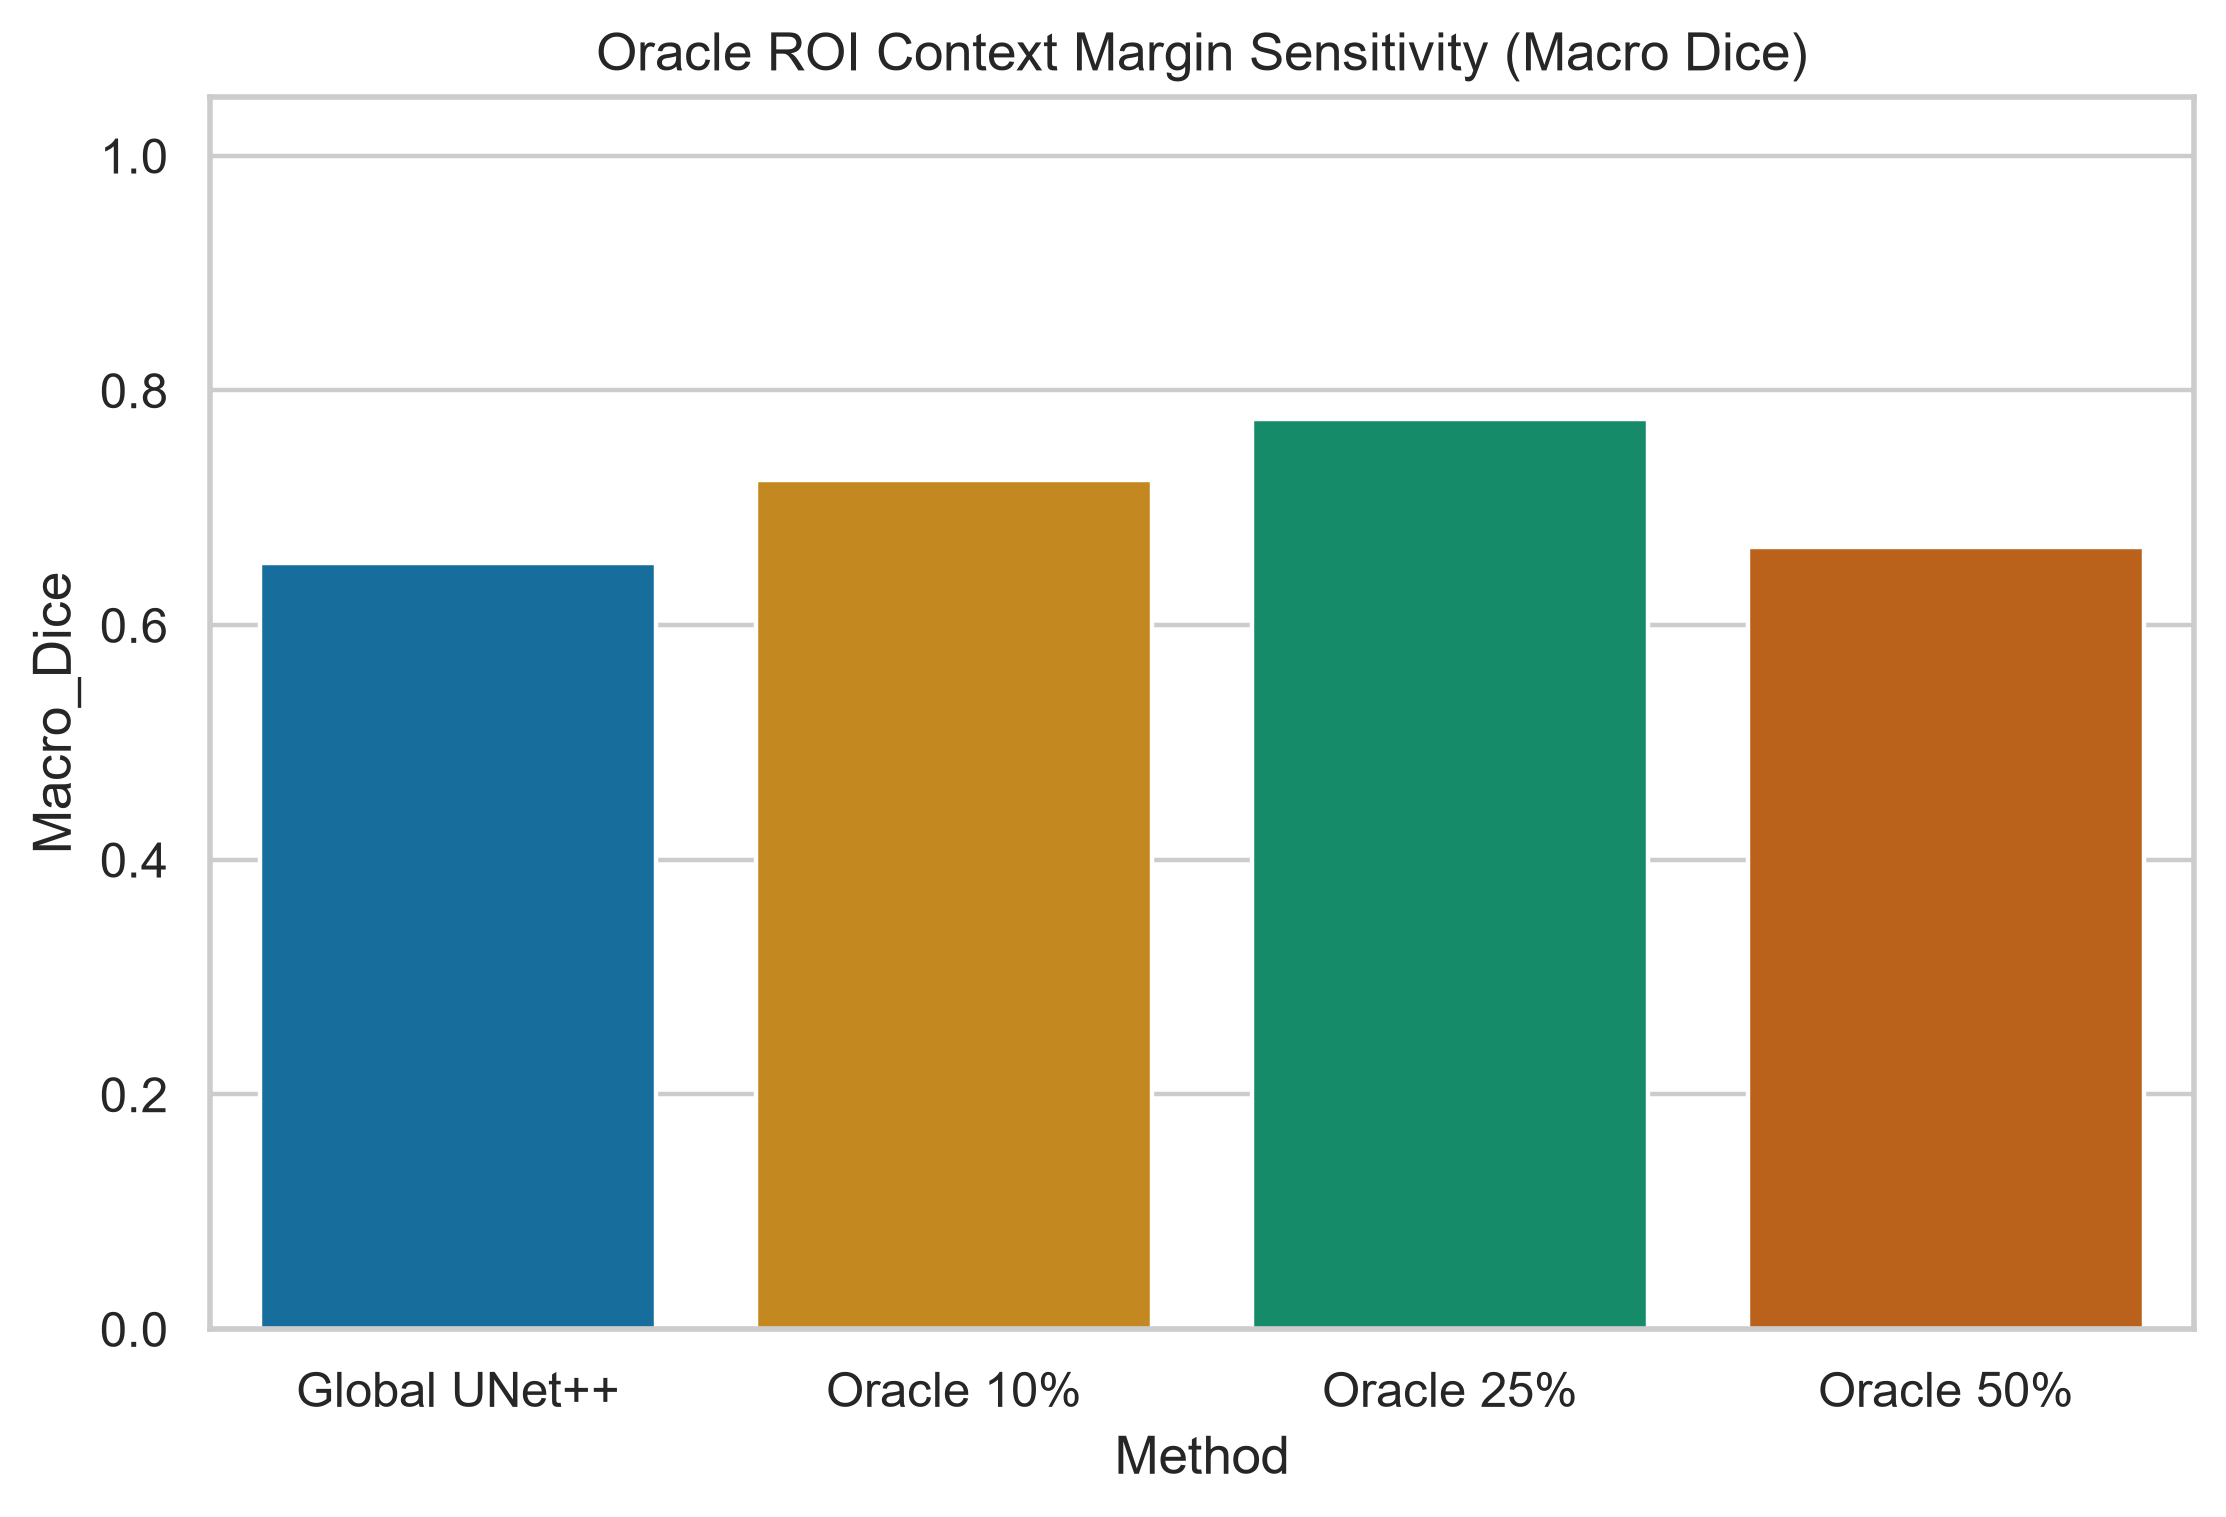

In [3]:
display(summary)
display(Image(filename=str(F/'phase12_margin_sensitivity.png'),width=850))

## Paired FULL_FIELD Dice effect

,mean,median,Q1,Q3,improved,unchanged,worsened
0,0.12296,0.048689,-0.038665,0.210086,61,0,45


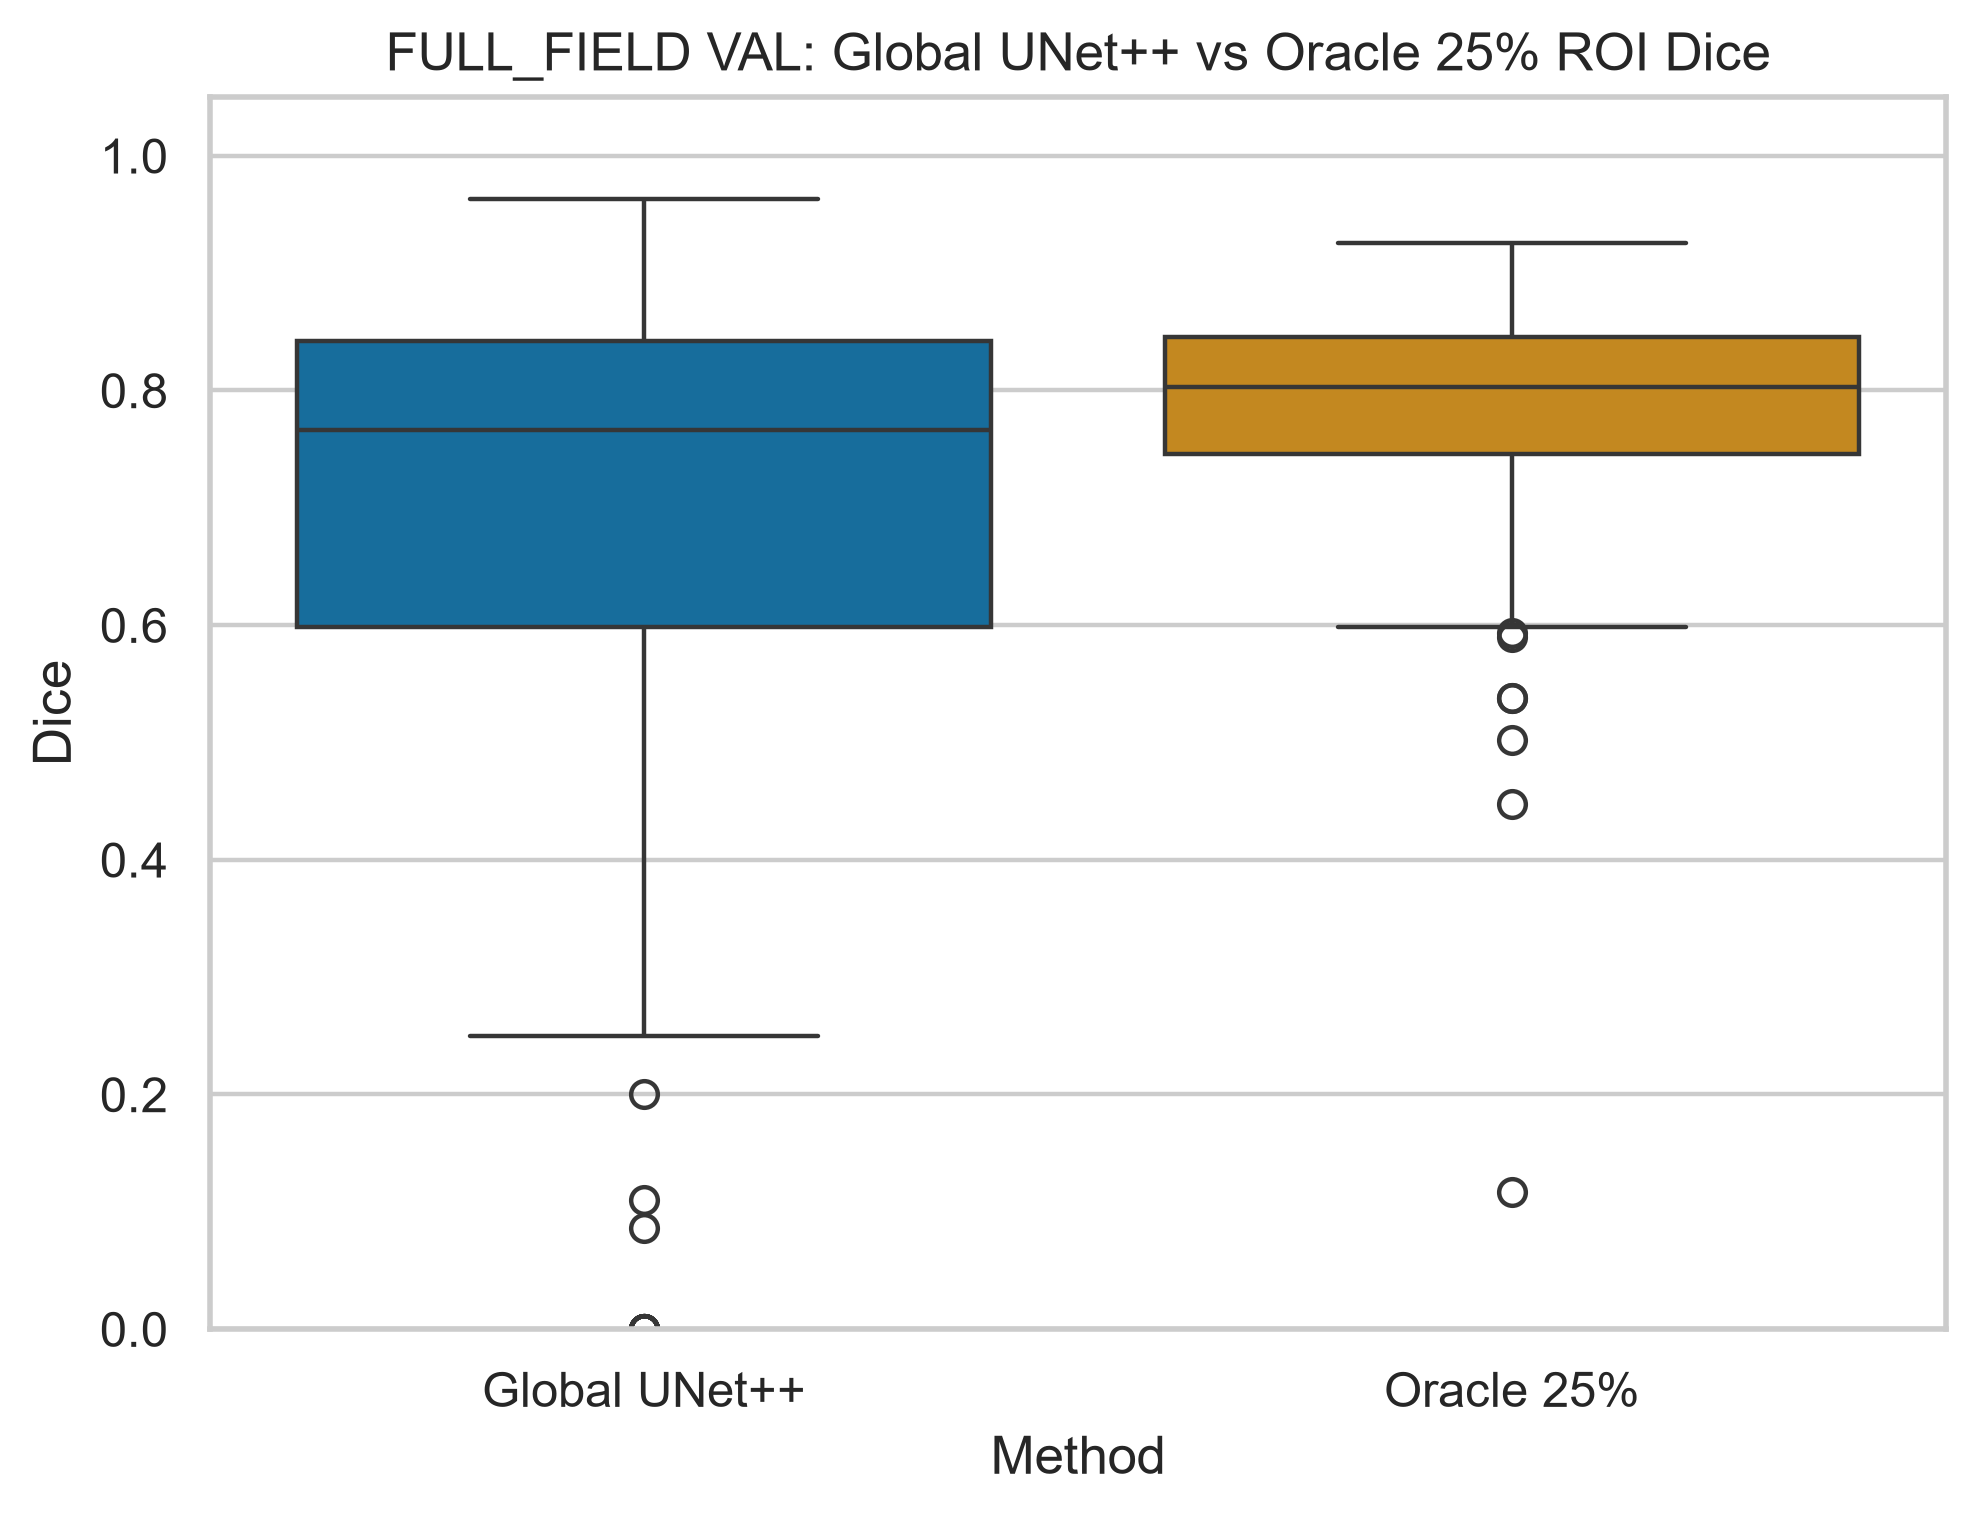

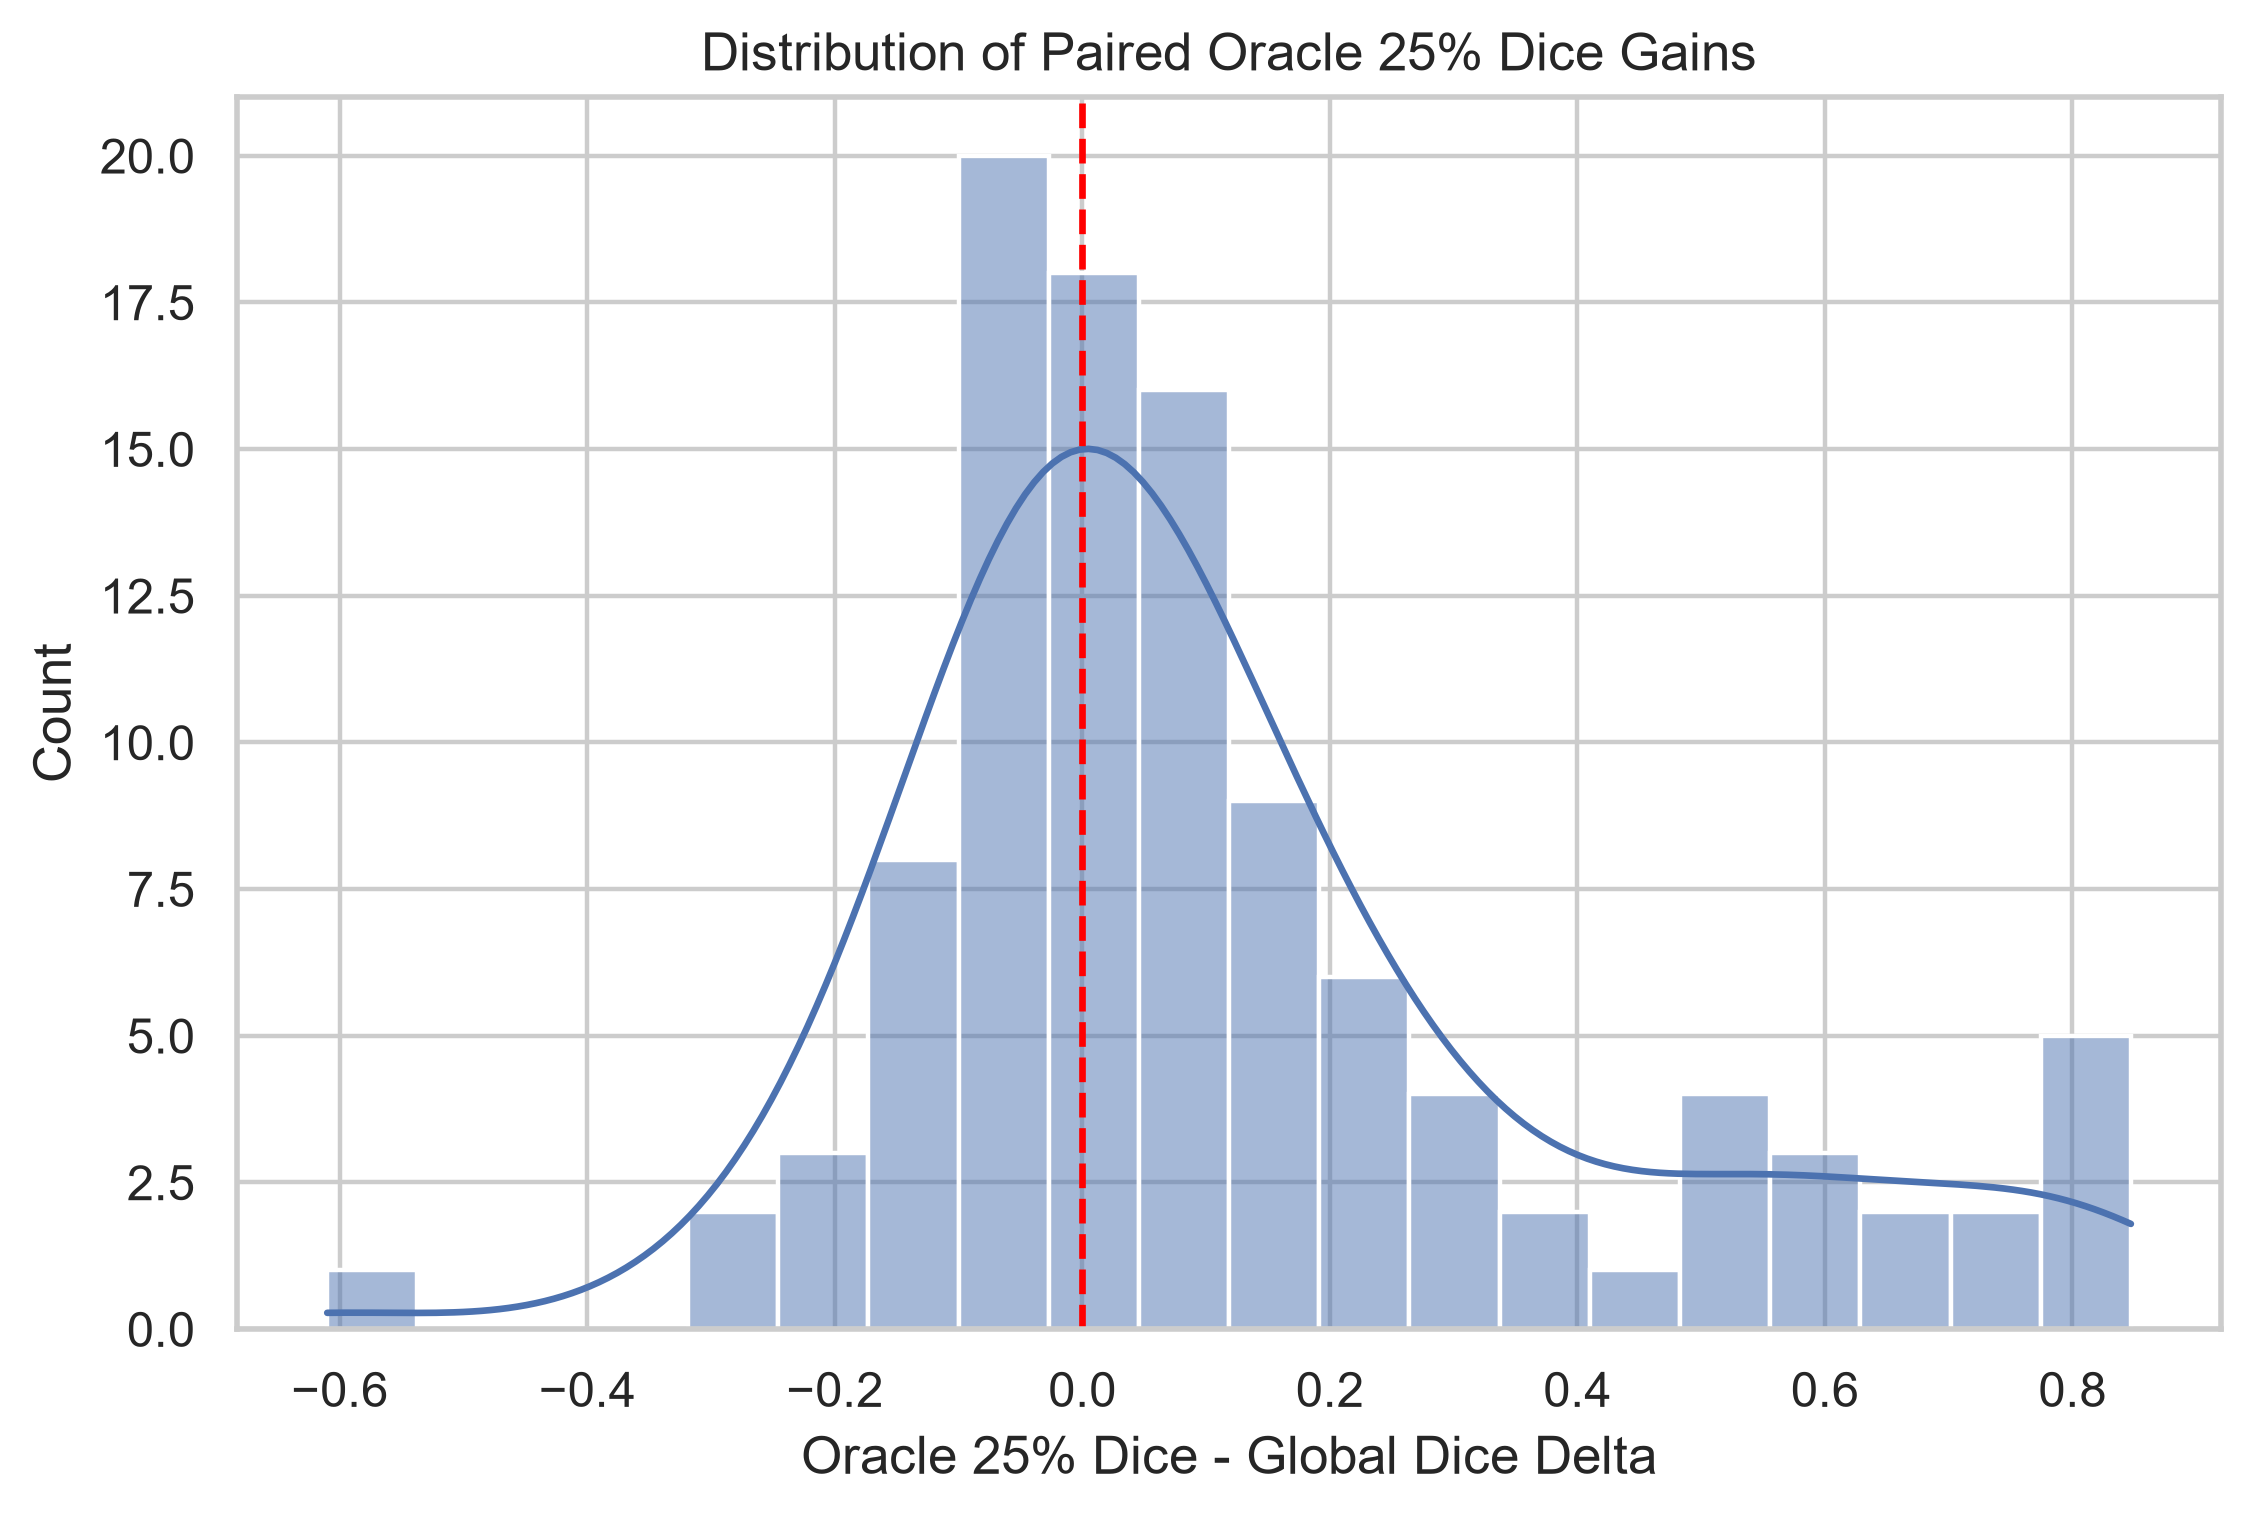

In [4]:
d=per_image.dice_delta_oracle25_minus_global
display(pd.DataFrame({'mean':[d.mean()],'median':[d.median()],'Q1':[d.quantile(.25)],'Q3':[d.quantile(.75)],'improved':[(d>0).sum()],'unchanged':[(d==0).sum()],'worsened':[(d<0).sum()]}))
display(Image(filename=str(F/'phase12_global_vs_oracle_dice.png'),width=750))
display(Image(filename=str(F/'phase12_dice_delta_distribution.png'),width=850))

## Original-space size recovery and TINY endpoint

,Stratum,GT_Components,Global_Detected,Global_Missed,Oracle25_Detected,Oracle25_Missed,Global_Recall,Oracle25_Recall,Delta_Recall,Global_Misses_Recovered,Global_Detections_Lost
0,TINY,73,57,16,72,1,0.780822,0.986301,0.205479,15,0
1,SMALL,29,25,4,29,0,0.862069,1.000000,0.137931,4,0
2,MEDIUM,36,32,4,36,0,0.888889,1.000000,0.111111,4,0
3,LARGE,18,17,1,18,0,0.944444,1.000000,0.055556,1,0


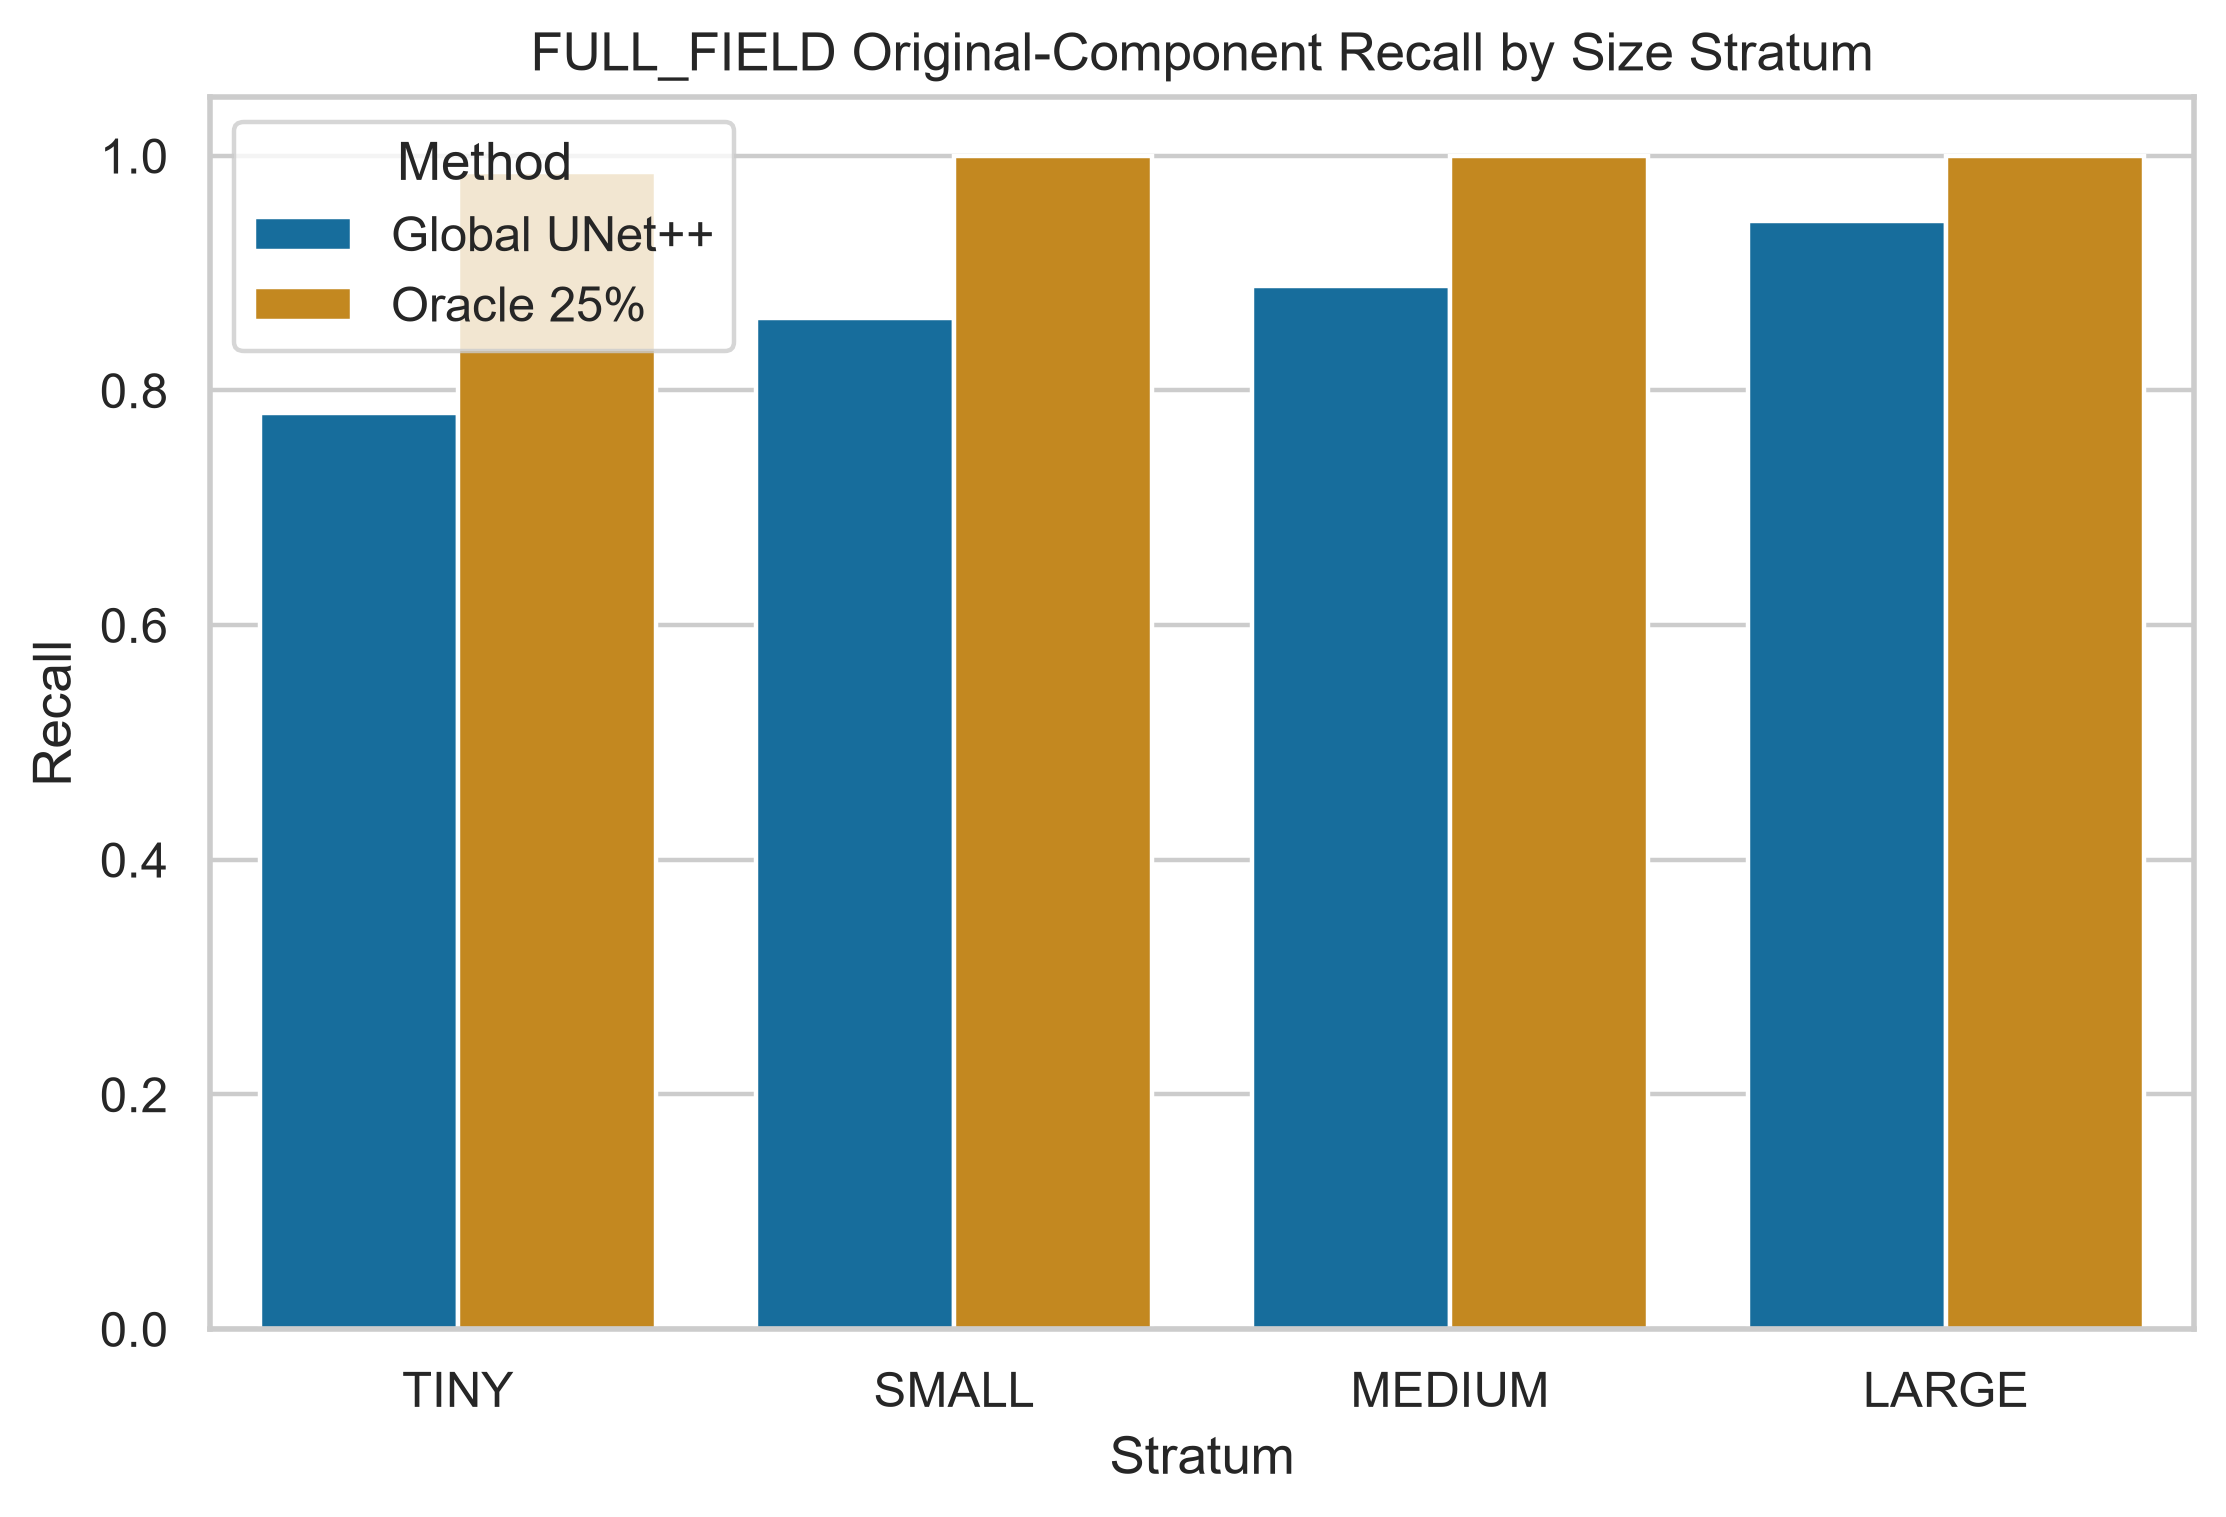

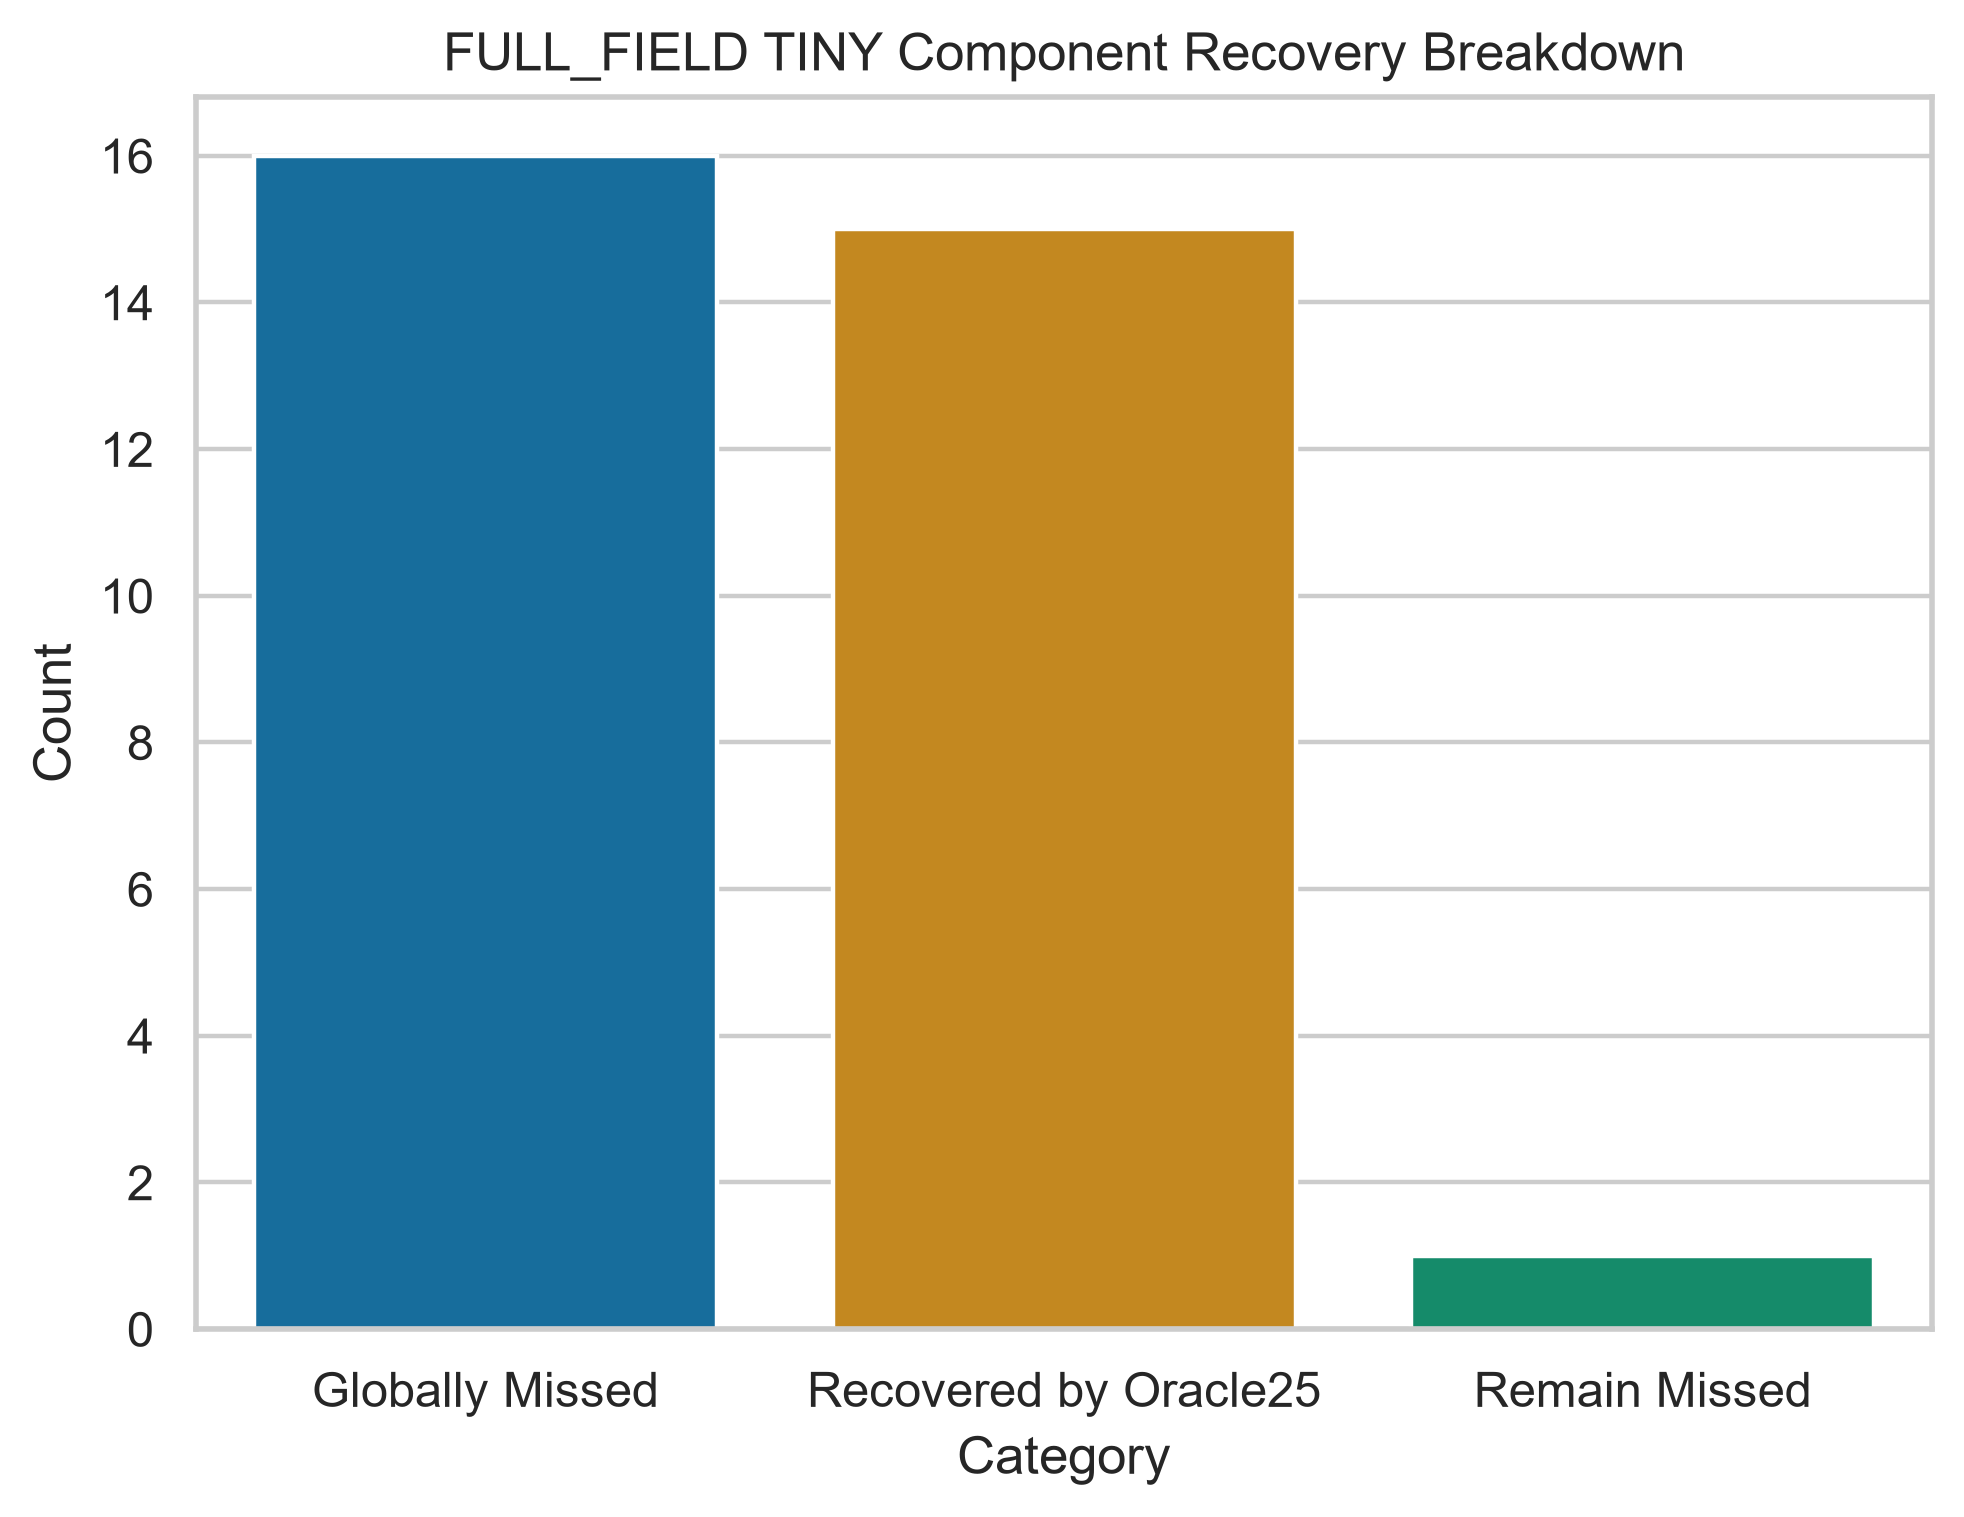

In [5]:
size=pd.read_csv(T/'phase12_oracle_roi_size_recovery.csv'); display(size)
display(Image(filename=str(F/'phase12_size_recall_global_vs_oracle.png'),width=850))
display(Image(filename=str(F/'phase12_tiny_recovery.png'),width=750))

## Multi-component and empty-prediction recovery

,Method,N_Multi_Images,Macro_Dice,Complete_Detections,Partial_Detections,Complete_Misses,Component_Recall,Mean_Fraction_Detected_Per_Image
0,Global UNet++,50,0.652216,36,10,4,0.82,0.82
1,Oracle 25%,50,0.777610,49,1,0,0.99,0.99


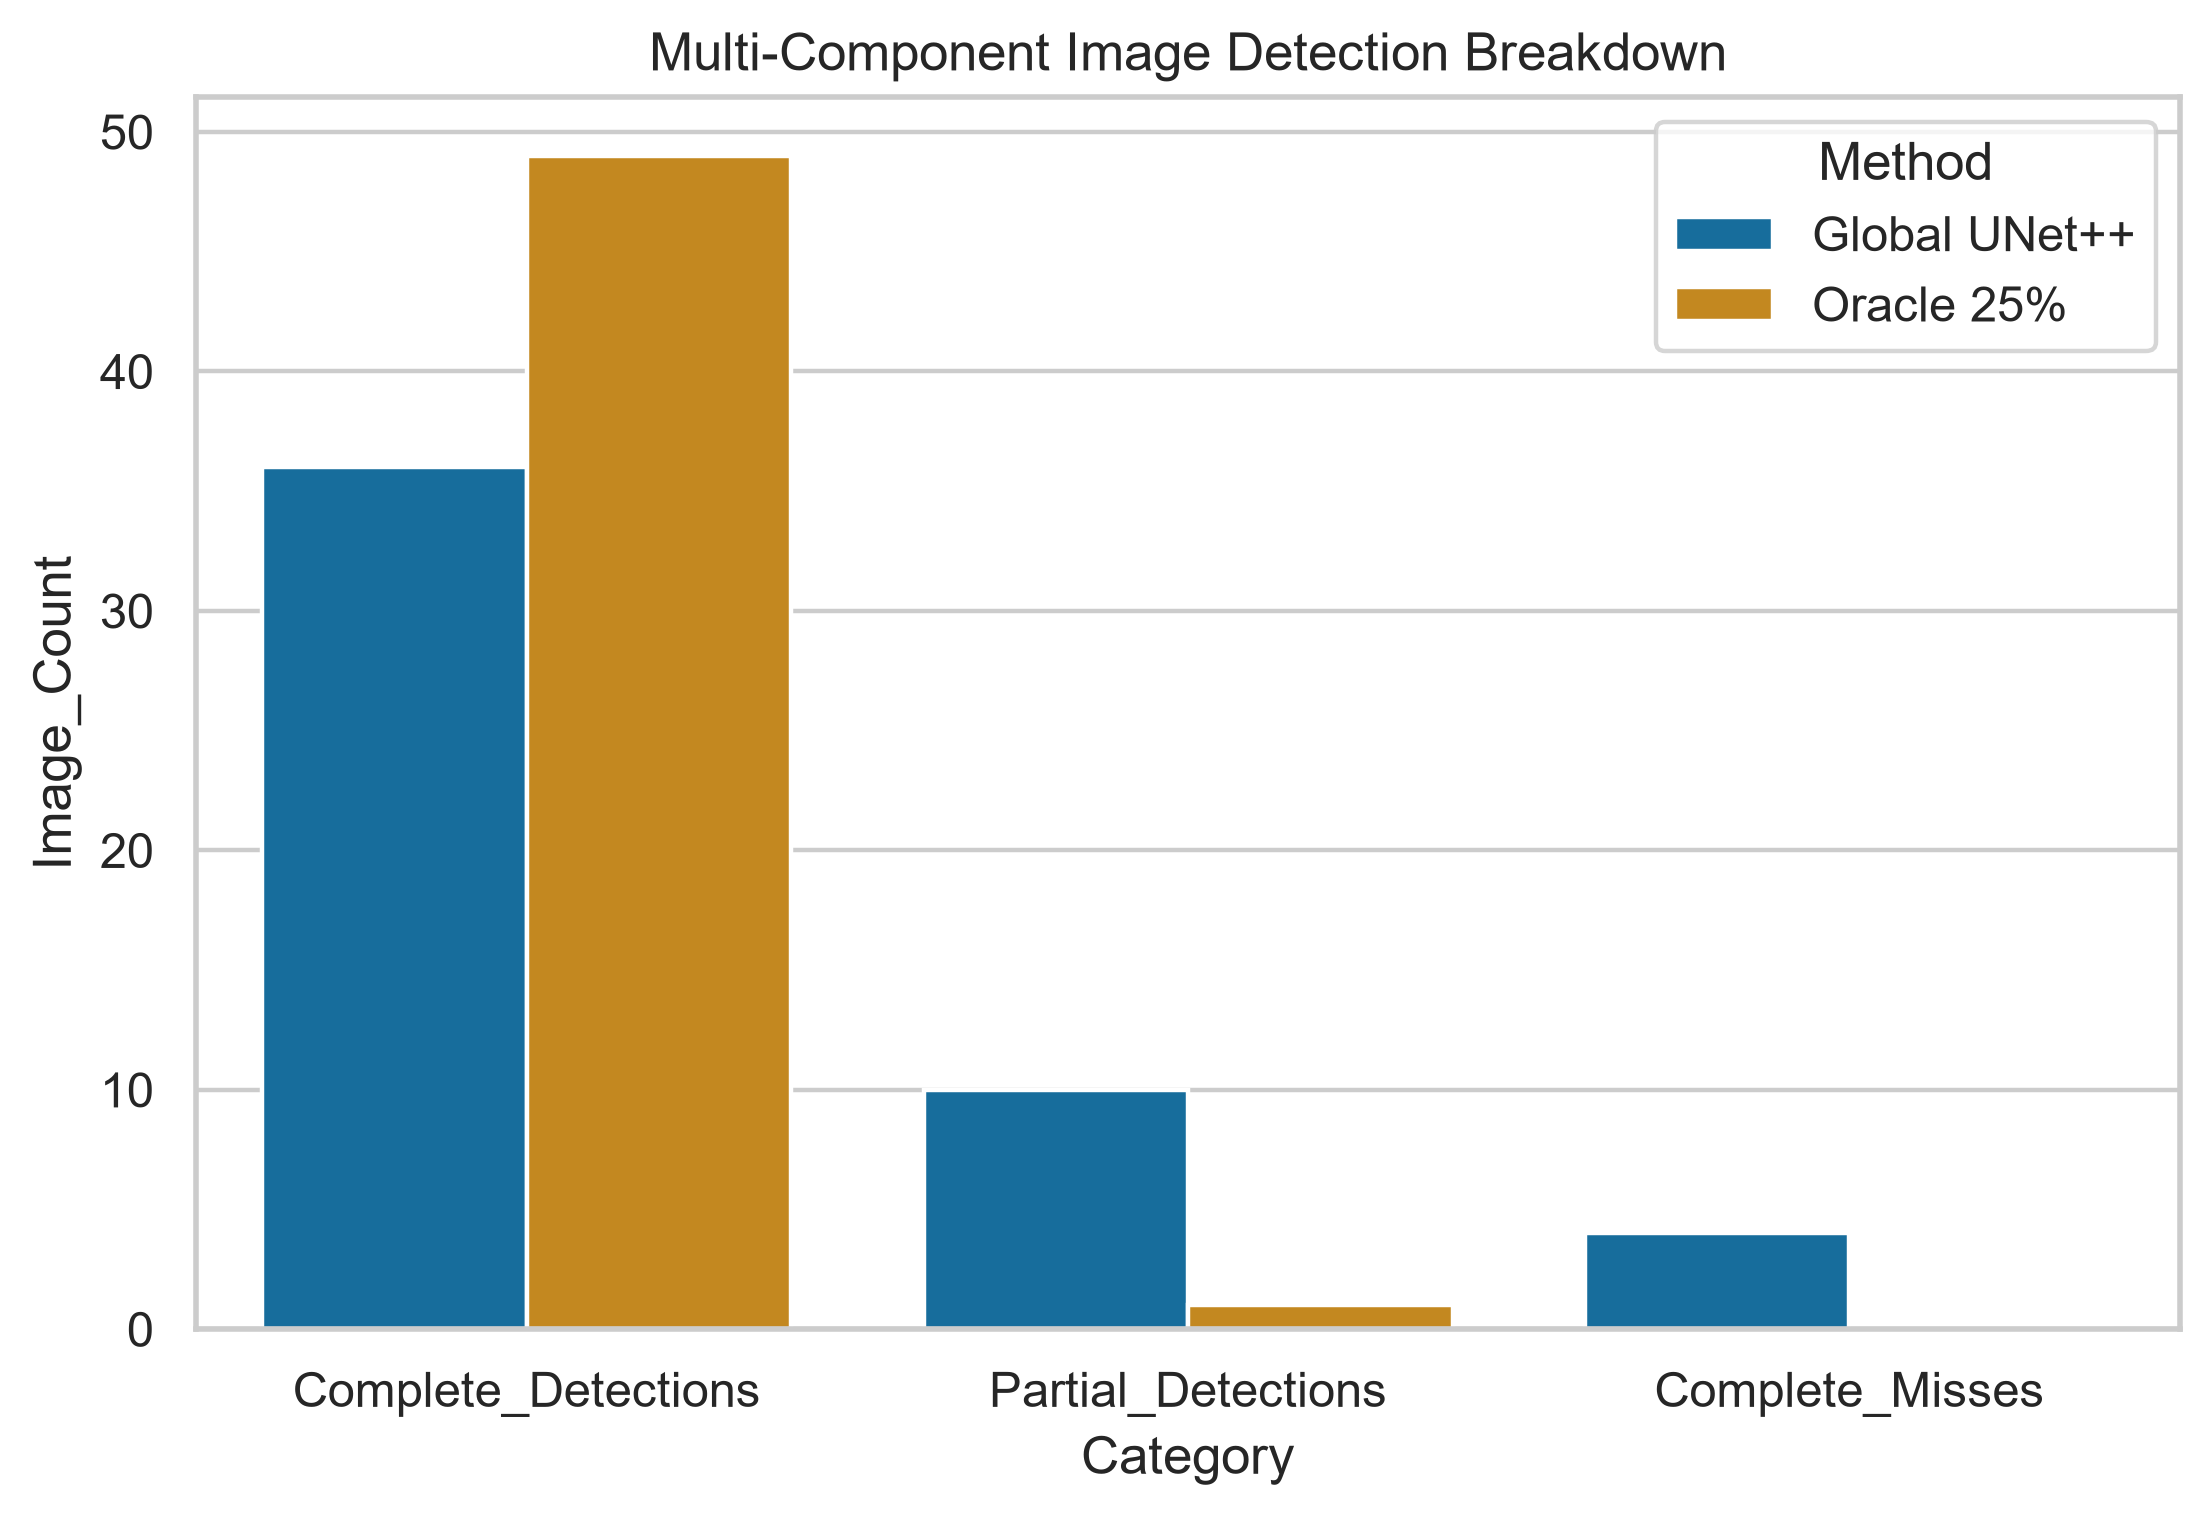

,sample_id,global_dice,oracle25_dice,oracle25_empty_prediction
16,b0473630de9211114c94c7dc0363ebd9,4.166667e-09,0.737235,False
24,8c8d2107815002b7913bd6a42f93b394,9.090909e-09,0.803063,False
26,ad4af1ce1b3dde6ad04fa095aacd92f5,8.333333e-09,0.447799,False
27,abe658fa57a12b1665a96d00beeffae0,1.265823e-09,0.847253,False
48,f860cbfe7c79e5772795a64bac5de7e7,4.347826e-09,0.819672,False
54,e1e165d69d6844c8a599786d865cdd21,2.272727e-09,0.765957,False
95,5dd4436a2065b8855ce1dfbed228bce7,1.234568e-09,0.593312,False


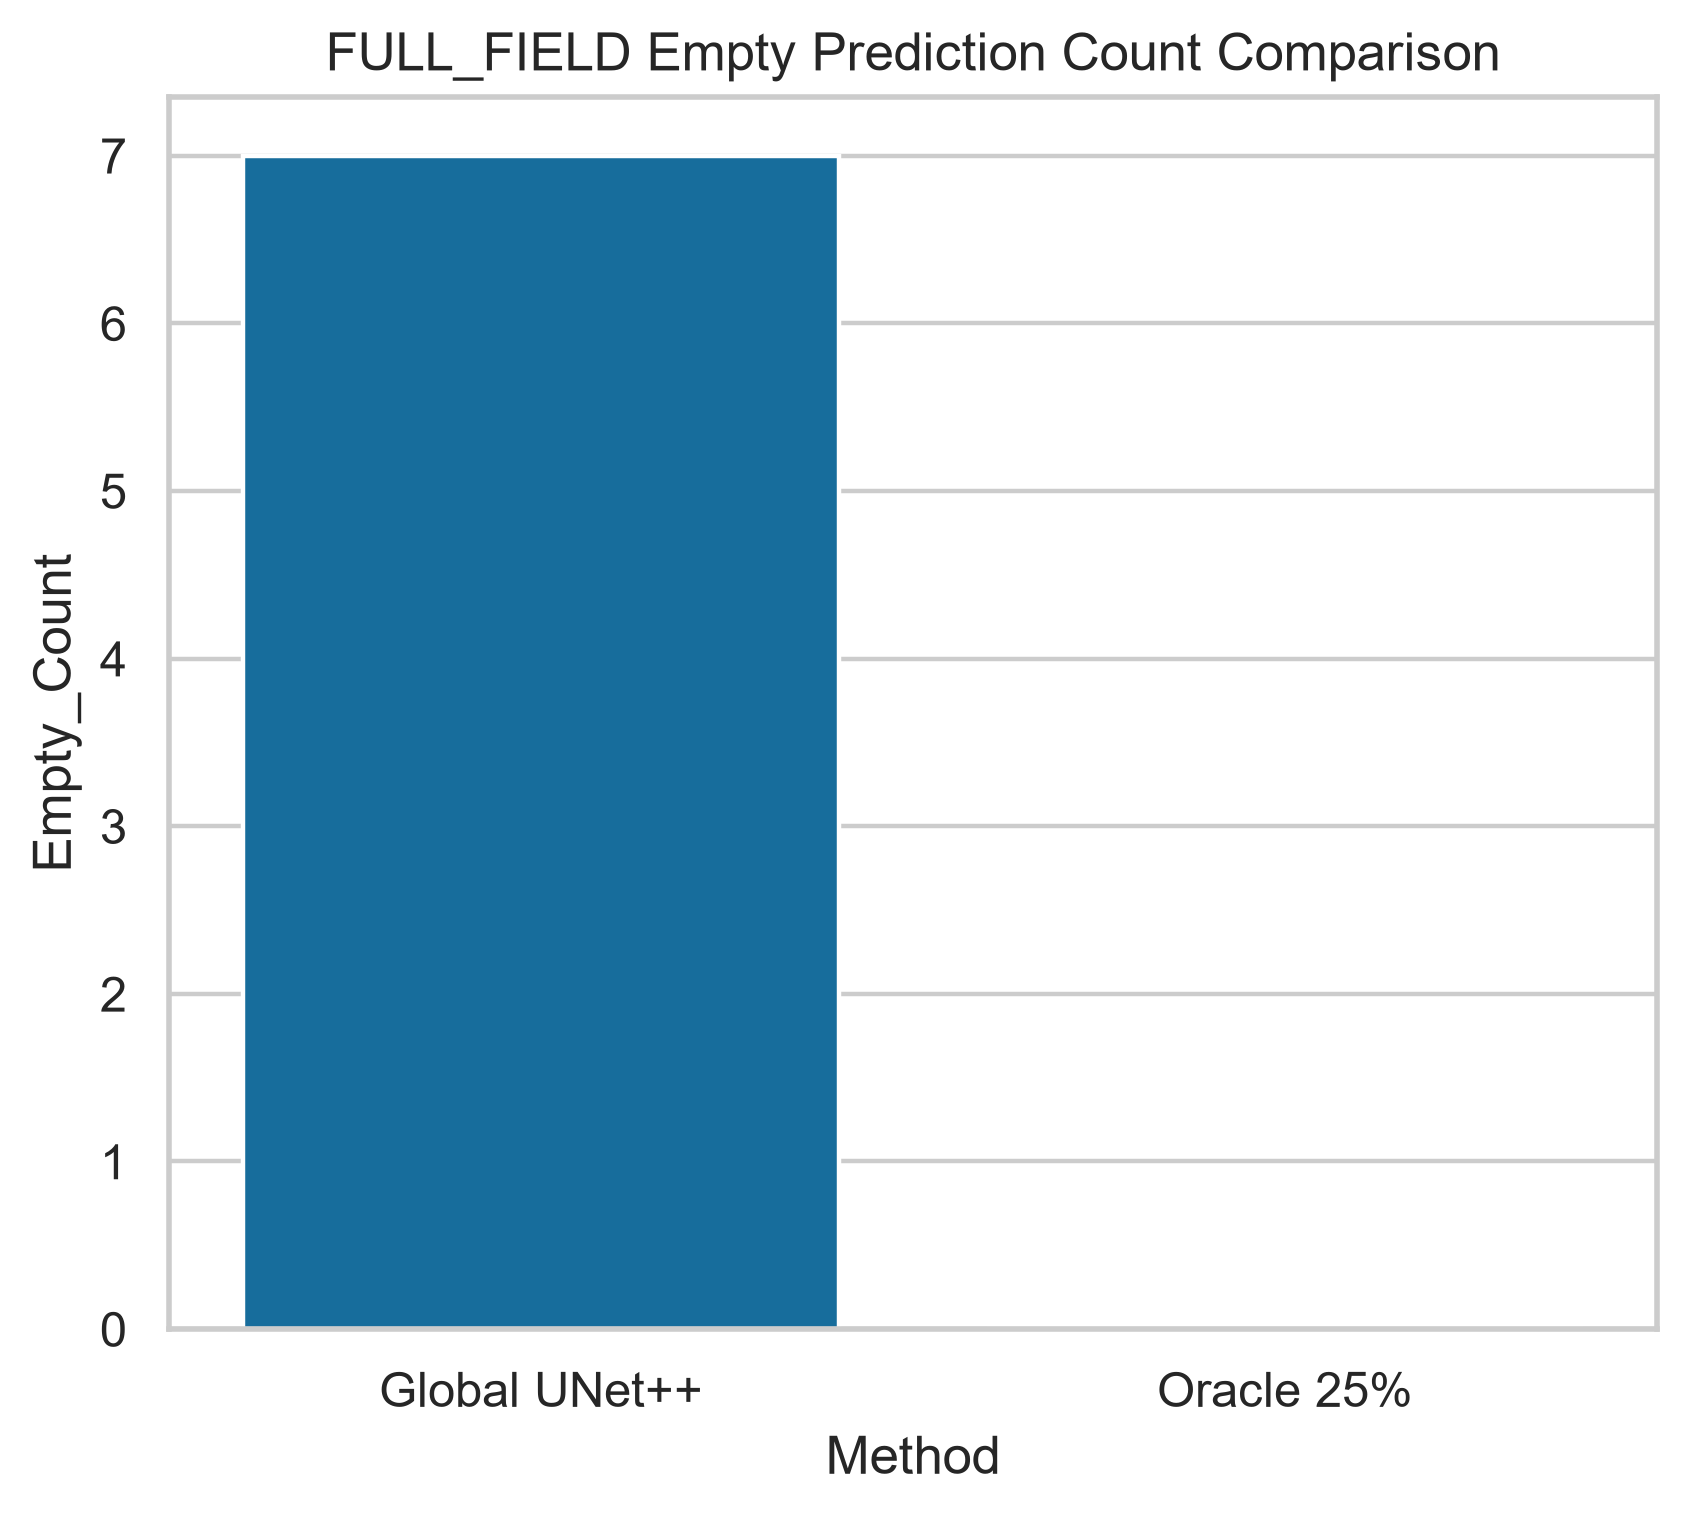

In [6]:
display(pd.read_csv(T/'phase12_oracle_roi_multicomponent.csv'))
display(Image(filename=str(F/'phase12_multicomponent_recovery.png'),width=850))
display(per_image[per_image.global_empty_prediction][['sample_id','global_dice','oracle25_dice','oracle25_empty_prediction']])
display(Image(filename=str(F/'phase12_empty_prediction_recovery.png'),width=650))

## Effective image-space magnification

,count,mean,std,min,25%,50%,75%,max
kub_size_v1_stratum,,,,,,,,
LARGE,18.0,1.759916,0.806347,0.709141,1.020274,1.597539,2.480176,3.084337
MEDIUM,36.0,4.056213,0.677330,2.828729,3.531034,4.031496,4.471874,5.446809
SMALL,29.0,6.513280,1.130915,4.491228,5.752809,6.243902,7.314286,8.827586
TINY,73.0,10.195621,2.163595,6.918919,8.533333,10.240000,11.130435,15.058824


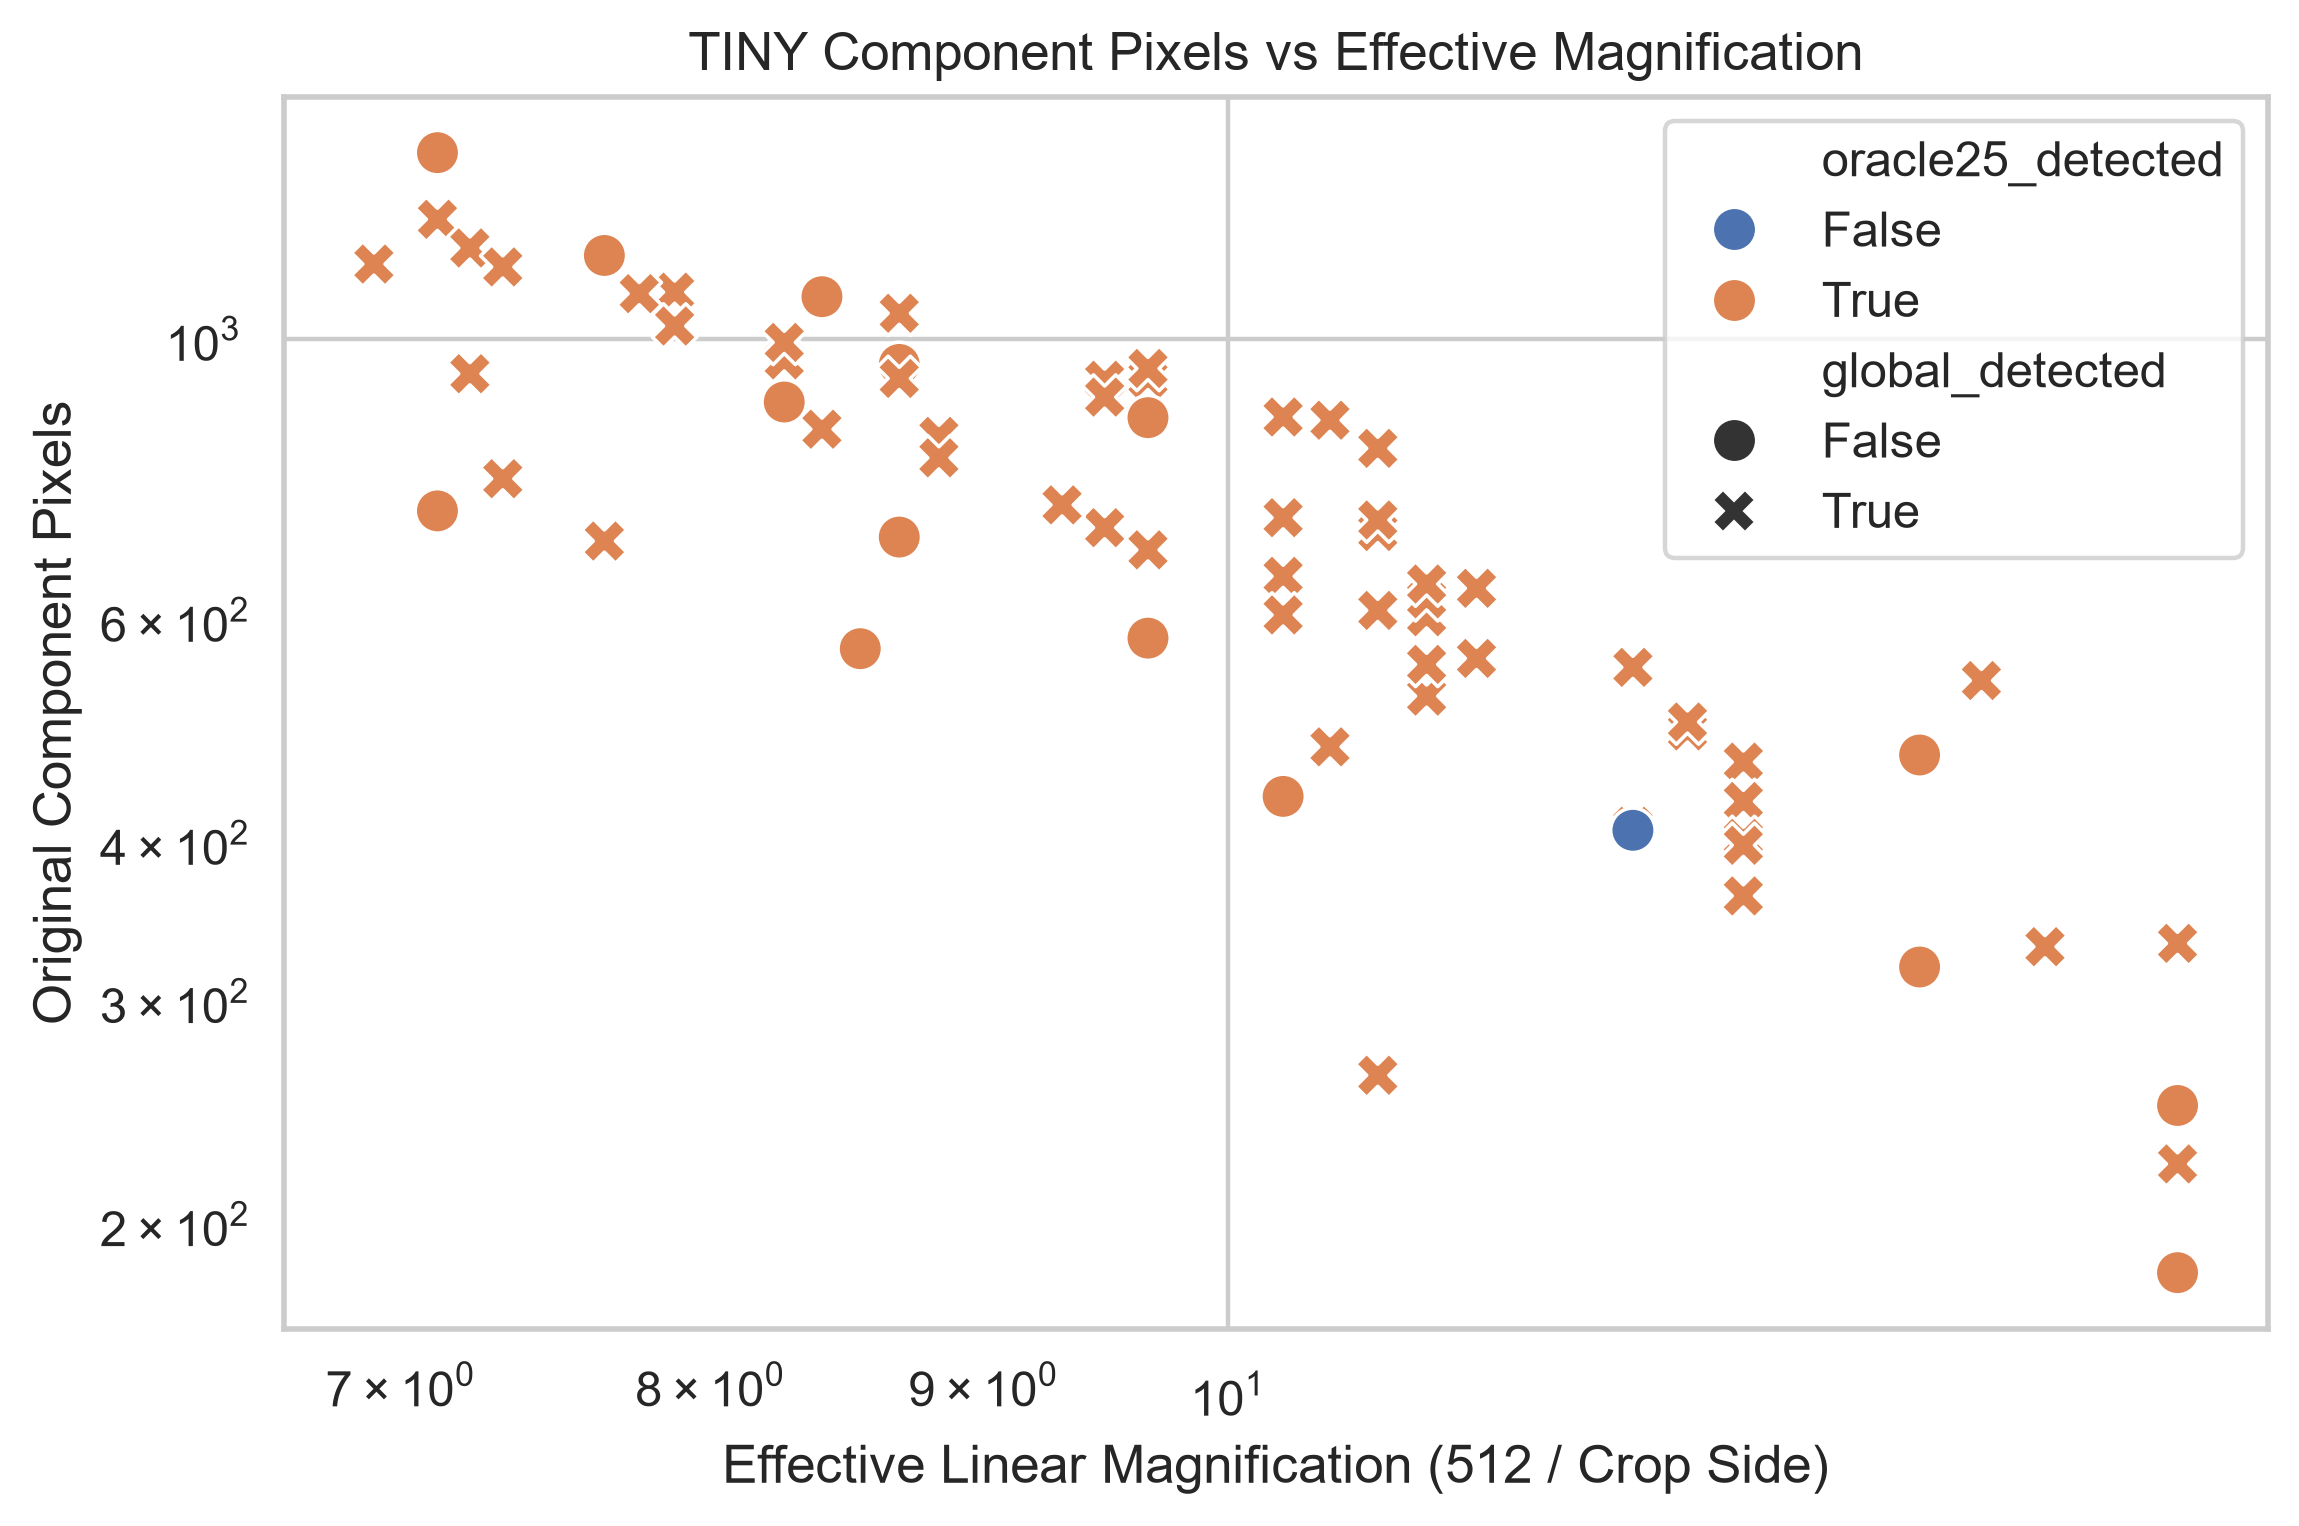

In [7]:
display(geometry.groupby('kub_size_v1_stratum').mag_25.describe())
display(Image(filename=str(F/'phase12_magnification_vs_recovery.png'),width=850))

## Deterministic Global-vs-Oracle panel

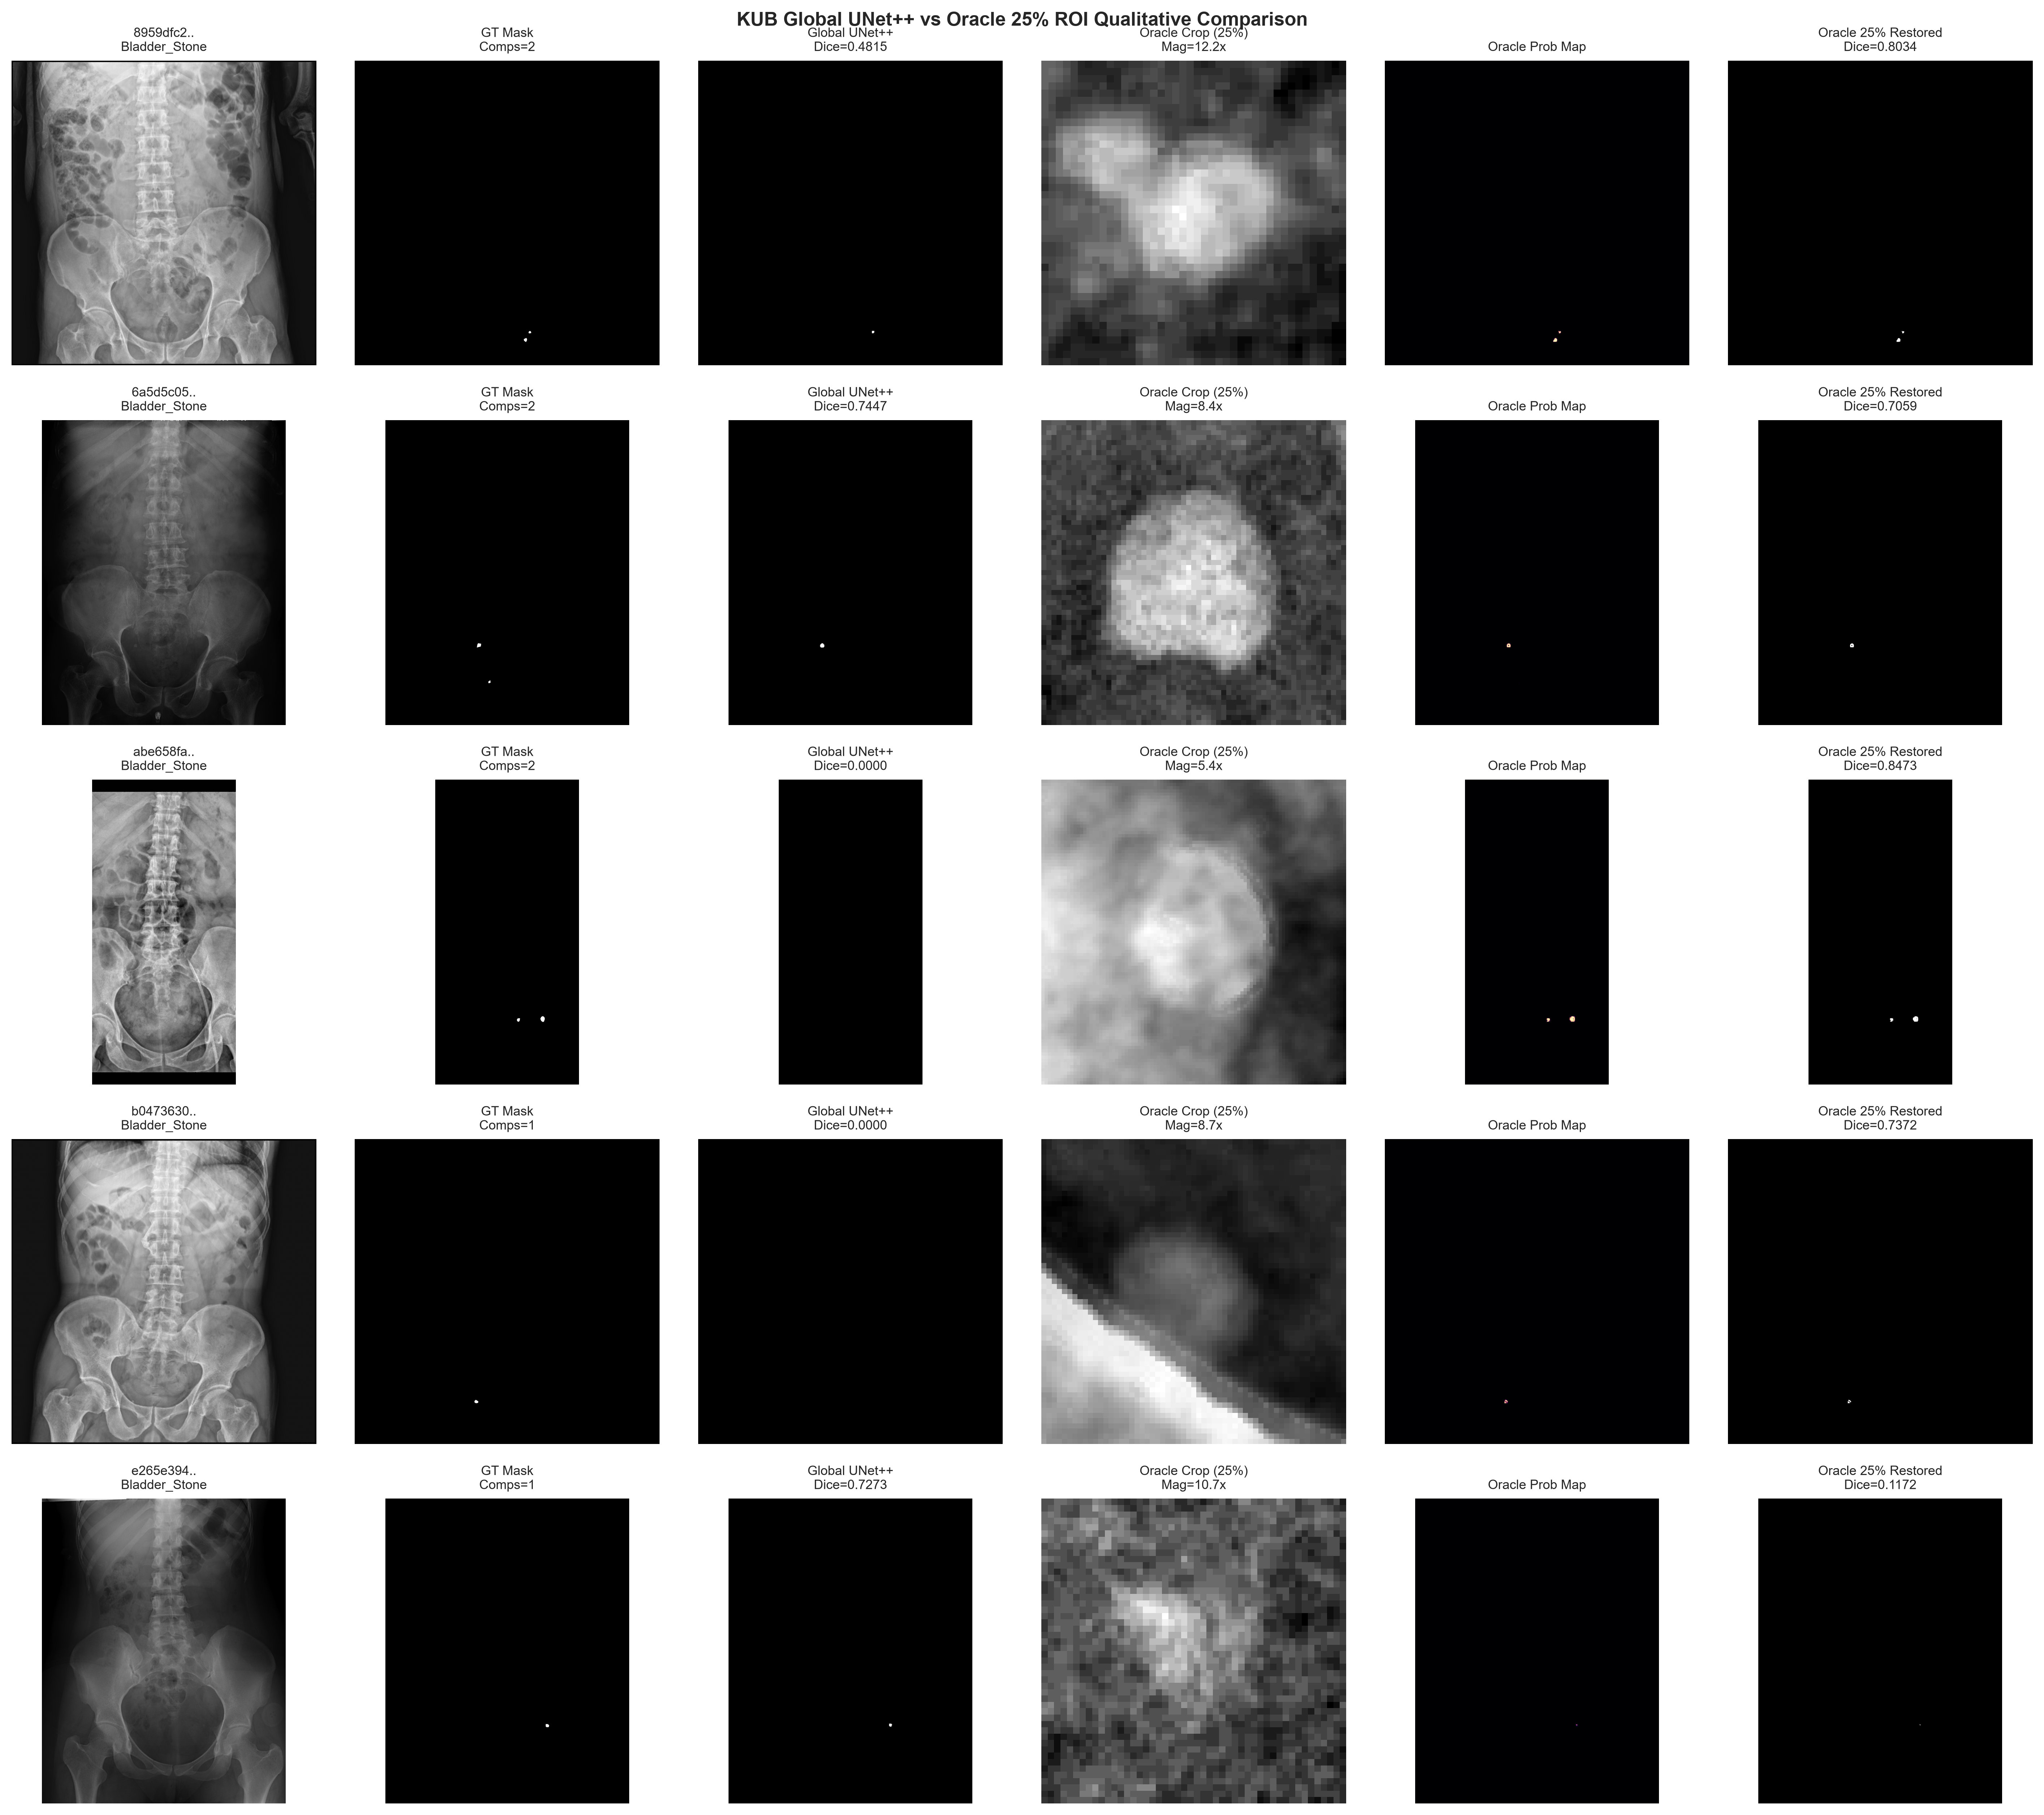

In [8]:
display(Image(filename=str(Q/'phase12_global_vs_oracle_panel.png'),width=1300))

## Limitations and FP caveat

Oracle ROI is artificially advantaged: GT constrains inference regions, so Oracle-constrained FP metrics are not fairly comparable to deployable global inference. This is a localization/resolution upper bound, not a clinical method. Results use one VAL split and one frozen model; no significance or causal superiority claim is made.

## Phase-13 implication

The observed gain motivates development and evaluation of predicted ROI proposals. It does **not** prove that a deployable regional method will reproduce the Oracle gain. **Phase 13 was not executed. TEST NOT ACCESSED. STOP.**